# Task 1a — Matplotlib Pyplot Tutorial

**Course:** Modern Data Analysis / Session 5: Graphics  
**Assignment route:** Task 1a — read the Matplotlib *Pyplot tutorial* and execute its examples  
**Student:** Ugochukwu Prince Ifunanya

## Aim
This notebook follows the official Matplotlib Pyplot tutorial, runs the principal code examples, and explains the purpose of each command and important parameter in simple English. The goal is to demonstrate how to create, format, label, annotate, and arrange plots using `matplotlib.pyplot`.

**Official source:** https://matplotlib.org/stable/tutorials/pyplot.html

## Environment
The notebook uses Python, Matplotlib, and NumPy. In Google Colab, these packages are usually pre-installed. Run the notebook from top to bottom using **Runtime → Run all** so that all plots and outputs are saved.

## 1. Import the libraries

`matplotlib.pyplot` provides plotting functions. NumPy creates and manipulates numerical arrays used in several examples.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

print("Matplotlib version:", plt.matplotlib.__version__)
print("NumPy version:", np.__version__)

Matplotlib version: 3.10.0
NumPy version: 2.1.3


## 2. Introduction to `pyplot`: a simple line plot

This is the tutorial's first example. When only one list is passed to `plt.plot`, Matplotlib treats it as the **y-values** and automatically uses x-values `0, 1, 2, 3`.

- `plt.plot(...)` draws the line.
- `plt.ylabel(...)` labels the vertical axis.
- `plt.show()` displays the figure.

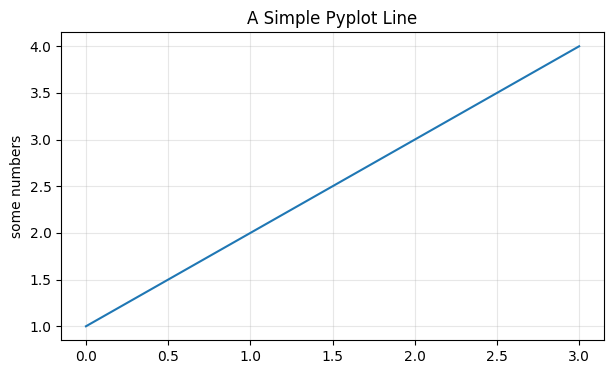

In [2]:
plt.figure(figsize=(7, 4))
plt.plot([1, 2, 3, 4])
plt.ylabel("some numbers")
plt.title("A Simple Pyplot Line")
plt.grid(True, alpha=0.3)
plt.show()

## 3. Plot explicit x- and y-values

Providing two sequences makes the first sequence the x-values and the second the y-values. Here the plot shows the points `(1,1)`, `(2,4)`, `(3,9)`, and `(4,16)`, connected by a line.

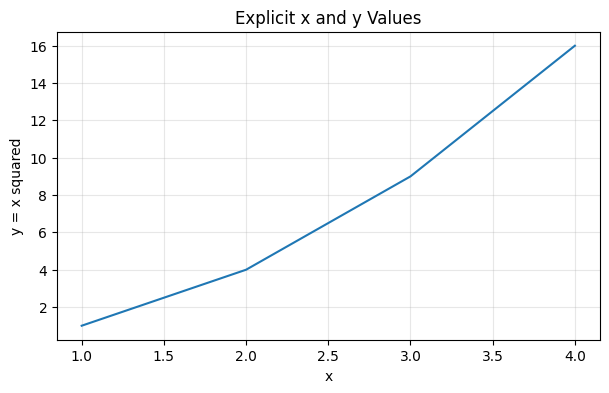

In [3]:
plt.figure(figsize=(7, 4))
plt.plot([1, 2, 3, 4], [1, 4, 9, 16])
plt.title("Explicit x and y Values")
plt.xlabel("x")
plt.ylabel("y = x squared")
plt.grid(True, alpha=0.3)
plt.show()

## 4. Formatting the plot style and axis range

The format string `'ro'` means **red circle markers** without connecting lines. `plt.axis((xmin, xmax, ymin, ymax))` sets the visible x- and y-axis limits.

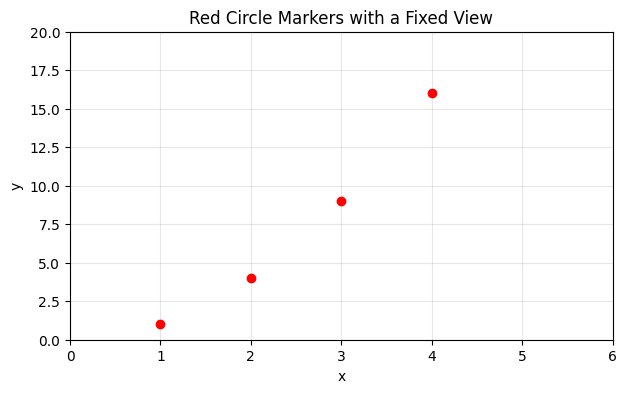

In [4]:
plt.figure(figsize=(7, 4))
plt.plot([1, 2, 3, 4], [1, 4, 9, 16], "ro")
plt.axis((0, 6, 0, 20))
plt.title("Red Circle Markers with a Fixed View")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()

## 5. Plot several NumPy-based series with different styles

`np.arange(0., 5., 0.2)` creates values from 0 up to (but not including) 5, spaced by 0.2. The three series use different format strings:

- `'r--'`: red dashed line
- `'bs'`: blue square markers
- `'g^'`: green triangle markers

The example shows that one `plt.plot` call can draw multiple series.

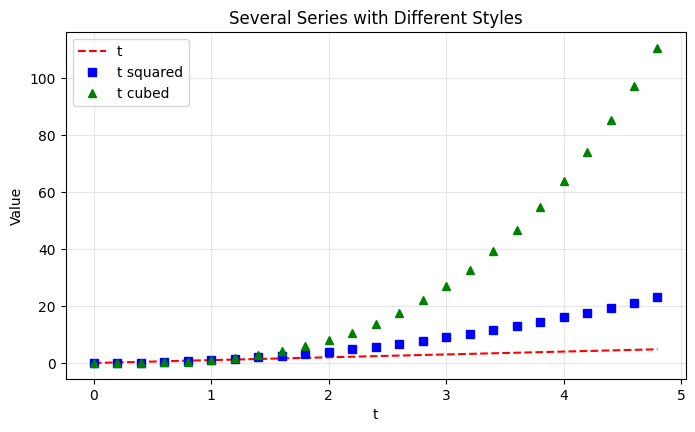

In [5]:
t = np.arange(0., 5., 0.2)

plt.figure(figsize=(8, 4.5))
plt.plot(t, t, "r--", t, t**2, "bs", t, t**3, "g^")
plt.title("Several Series with Different Styles")
plt.xlabel("t")
plt.ylabel("Value")
plt.legend(["t", "t squared", "t cubed"])
plt.grid(True, alpha=0.3)
plt.show()

## 6. Plotting from a dictionary using keyword strings

When `data=` is supplied, strings such as `'a'` and `'b'` refer to keys in the dictionary. In `plt.scatter`, `c` controls marker colour and `s` controls marker area/size. This example uses a fixed random seed so the output is reproducible.

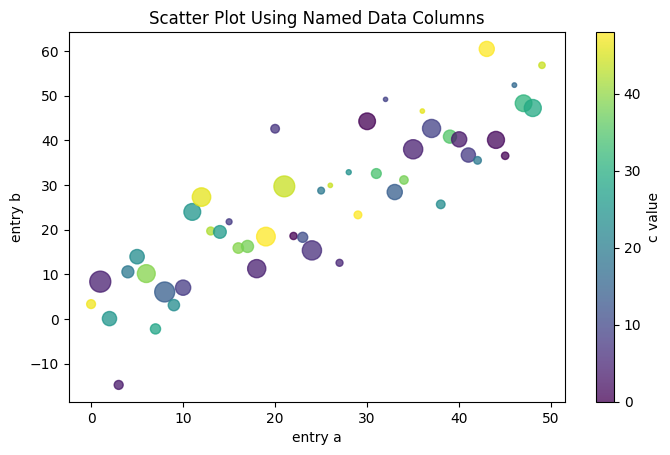

In [6]:
np.random.seed(7)
data = {
    "a": np.arange(50),
    "c": np.random.randint(0, 50, 50),
    "d": np.random.randn(50)
}
data["b"] = data["a"] + 10 * np.random.randn(50)
data["d"] = np.abs(data["d"]) * 100

plt.figure(figsize=(8, 4.8))
plt.scatter("a", "b", c="c", s="d", data=data, alpha=0.75, cmap="viridis")
plt.xlabel("entry a")
plt.ylabel("entry b")
plt.title("Scatter Plot Using Named Data Columns")
plt.colorbar(label="c value")
plt.show()

## 7. Plotting categorical variables

Matplotlib can use category labels directly on the x-axis. `plt.subplot(131)`, `plt.subplot(132)`, and `plt.subplot(133)` create the first, second, and third panels in a 1-row by 3-column layout. The three panels show the same categories as a bar chart, scatter plot, and line plot.

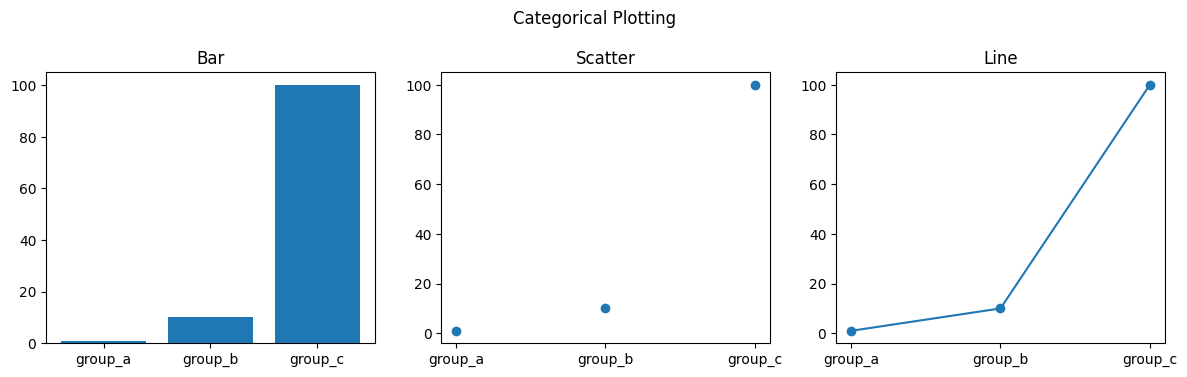

In [7]:
names = ["group_a", "group_b", "group_c"]
values = [1, 10, 100]

plt.figure(figsize=(12, 3.8))
plt.subplot(131)
plt.bar(names, values)
plt.title("Bar")

plt.subplot(132)
plt.scatter(names, values)
plt.title("Scatter")

plt.subplot(133)
plt.plot(names, values, marker="o")
plt.title("Line")

plt.suptitle("Categorical Plotting")
plt.tight_layout()
plt.show()

## 8. Controlling line properties

Line appearance can be adjusted through keyword arguments such as `linewidth`. The tutorial also demonstrates that `plt.plot` returns line objects, which can be changed with methods or `plt.setp`. The following code demonstrates both approaches.

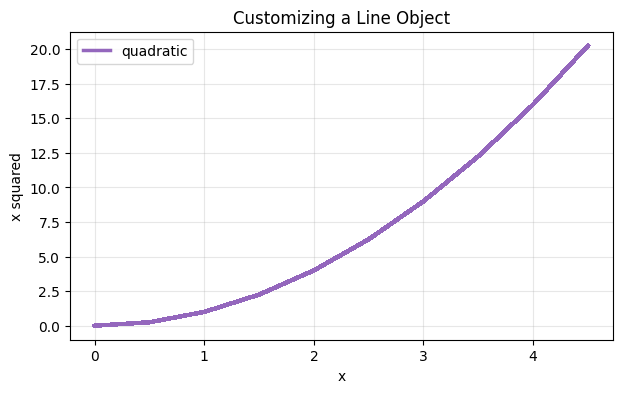

Line color: tab:purple
Line width: 2.5


In [8]:
x = np.arange(0, 5, 0.5)
y = x**2

plt.figure(figsize=(7, 4))
line, = plt.plot(x, y, "-", linewidth=2.0, label="quadratic")
line.set_antialiased(False)
plt.setp([line], color="tab:purple", linewidth=2.5)
plt.xlabel("x")
plt.ylabel("x squared")
plt.title("Customizing a Line Object")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Line color:", line.get_color())
print("Line width:", line.get_linewidth())

## 9. Working with multiple figures and Axes

The tutorial introduces `figure`, `subplot`, and the idea of the current figure and current Axes. The first figure below has two stacked panels. A second figure is then created to show that multiple figures can be managed separately.

`subplot(211)` is shorthand for `subplot(2, 1, 1)`: two rows, one column, first panel.

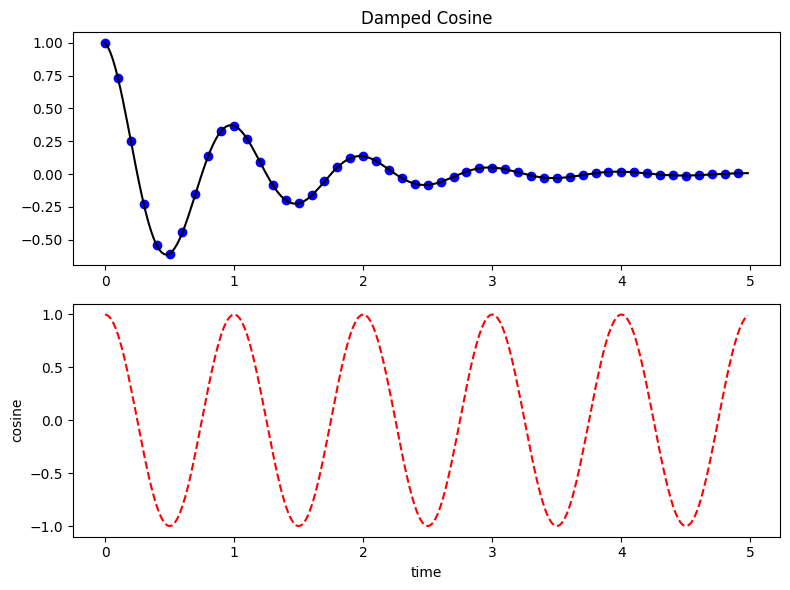

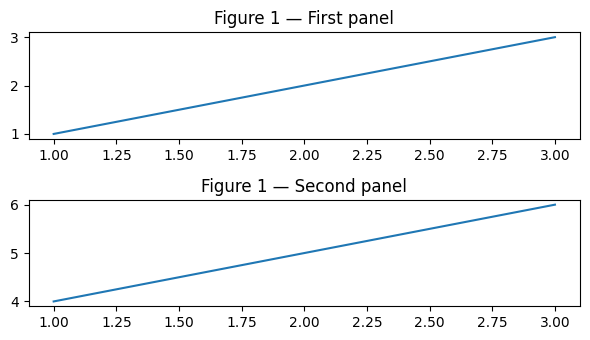

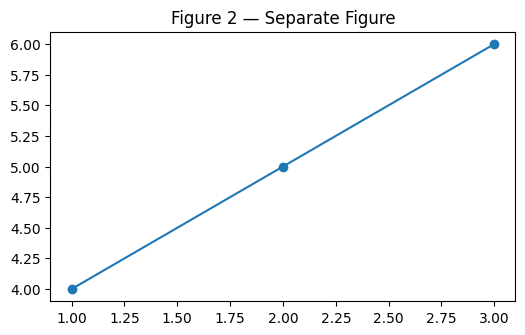

In [9]:
def f(t):
    return np.exp(-t) * np.cos(2 * np.pi * t)

t1 = np.arange(0.0, 5.0, 0.1)
t2 = np.arange(0.0, 5.0, 0.02)

plt.figure(figsize=(8, 6))
plt.subplot(211)
plt.plot(t1, f(t1), "bo", t2, f(t2), "k-")
plt.title("Damped Cosine")

plt.subplot(212)
plt.plot(t2, np.cos(2 * np.pi * t2), "r--")
plt.xlabel("time")
plt.ylabel("cosine")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 3.5))
plt.subplot(211)
plt.plot([1, 2, 3], [1, 2, 3])
plt.title("Figure 1 — First panel")

plt.subplot(212)
plt.plot([1, 2, 3], [4, 5, 6])
plt.title("Figure 1 — Second panel")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 3.5))
plt.plot([1, 2, 3], [4, 5, 6], marker="o")
plt.title("Figure 2 — Separate Figure")
plt.show()

## 10. Add labels, a title, a histogram, and text

`plt.hist` draws a histogram and returns the bin counts, bin edges, and bar patches. `density=True` normalizes the histogram so that the total area is approximately 1. `alpha` sets transparency. `plt.text` places text at a specified data coordinate.

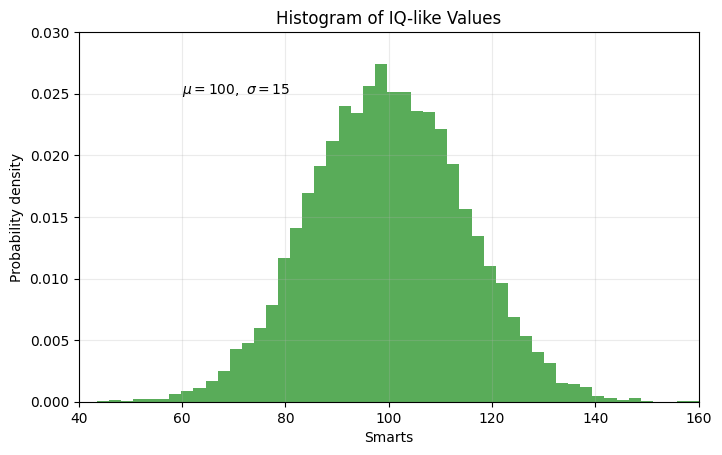

Number of observations: 10000
Number of histogram bins: 50
Sample mean: 99.8
Sample standard deviation: 14.82


In [10]:
mu, sigma = 100, 15
np.random.seed(19680801)
x = mu + sigma * np.random.randn(10000)

plt.figure(figsize=(8, 4.8))
n, bins, patches = plt.hist(
    x, 50, density=True, facecolor="green", alpha=0.65
)
plt.xlabel("Smarts")
plt.ylabel("Probability density")
plt.title("Histogram of IQ-like Values")
plt.text(60, 0.025, r"$\mu=100,\ \sigma=15$")
plt.axis([40, 160, 0, 0.03])
plt.grid(True, alpha=0.25)
plt.show()

print("Number of observations:", len(x))
print("Number of histogram bins:", len(bins) - 1)
print("Sample mean:", round(float(np.mean(x)), 2))
print("Sample standard deviation:", round(float(np.std(x, ddof=1)), 2))

## 11. Use mathematical expressions in plot text

Matplotlib supports mathematical notation in strings enclosed by dollar signs. The `r` prefix creates a raw string so that backslashes in the expression are preserved.

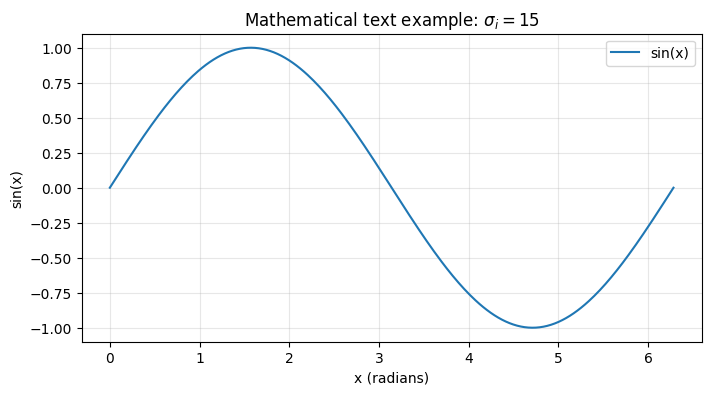

In [11]:
x = np.linspace(0, 2 * np.pi, 300)
y = np.sin(x)

plt.figure(figsize=(8, 4))
plt.plot(x, y, label="sin(x)")
plt.title(r"Mathematical text example: $\sigma_i = 15$")
plt.xlabel("x (radians)")
plt.ylabel("sin(x)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 12. Annotate a point on a plot

`plt.annotate` adds explanatory text and an arrow. `xy` identifies the point being highlighted; `xytext` identifies where the text should appear. `arrowprops` controls the arrow appearance.

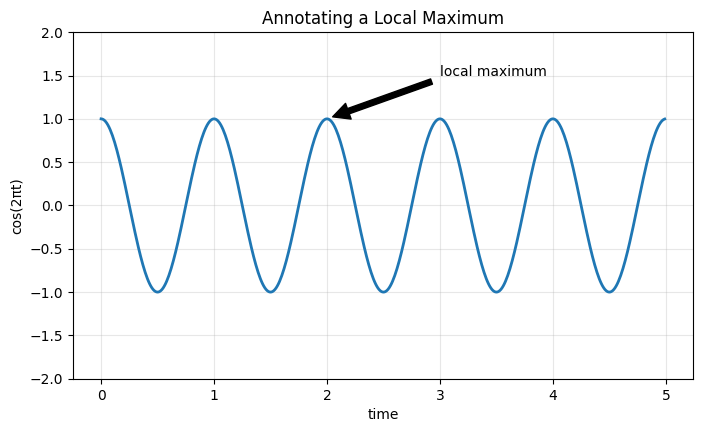

In [12]:
t = np.arange(0.0, 5.0, 0.01)
s = np.cos(2 * np.pi * t)

plt.figure(figsize=(8, 4.5))
plt.plot(t, s, linewidth=2)
plt.annotate(
    "local maximum",
    xy=(2, 1),
    xytext=(3, 1.5),
    arrowprops=dict(facecolor="black", shrink=0.05)
)
plt.ylim(-2, 2)
plt.xlabel("time")
plt.ylabel("cos(2πt)")
plt.title("Annotating a Local Maximum")
plt.grid(True, alpha=0.3)
plt.show()

## 13. Linear and nonlinear axis scales

The tutorial demonstrates linear, logarithmic, symmetric-logarithmic (`symlog`), and logit scales. This example uses a fixed random seed and keeps values strictly between 0 and 1 for the logit plot.

- `linear`: equal distances represent equal numeric differences.
- `log`: equal distances represent multiplicative changes.
- `symlog`: supports positive and negative values with a linear region around zero.
- `logit`: useful for values strictly between 0 and 1.

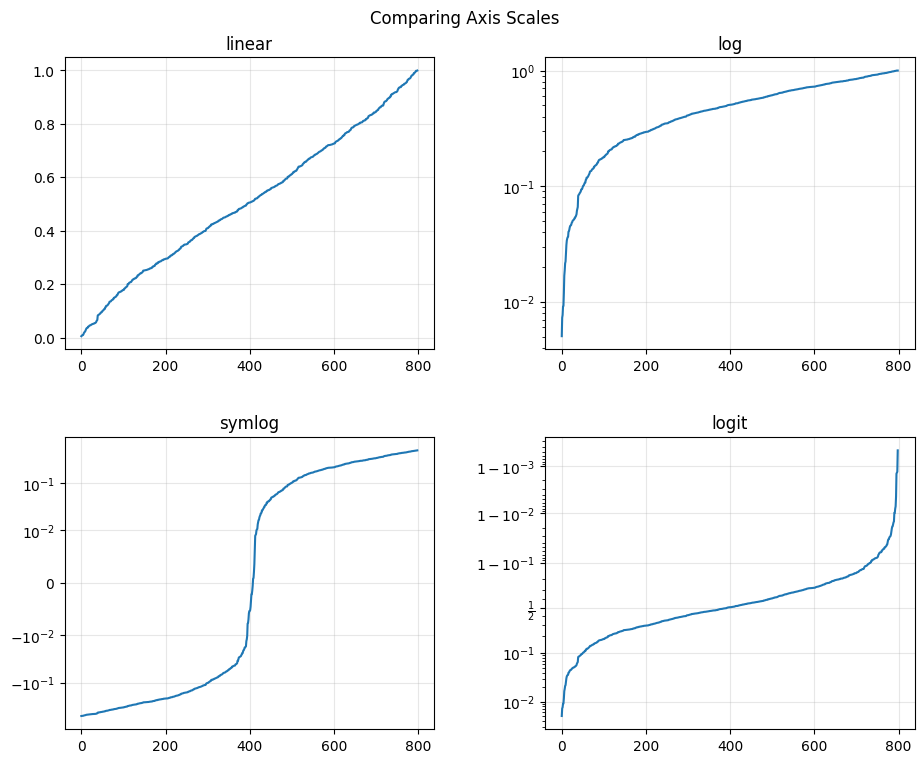

Values retained for scale comparison: 799
Minimum retained value: 0.005
Maximum retained value: 0.9995


In [13]:
np.random.seed(19680801)
y = np.random.normal(loc=0.5, scale=0.4, size=1000)
y = y[(y > 0) & (y < 1)]
y.sort()
x = np.arange(len(y))

plt.figure(figsize=(10, 8))

plt.subplot(221)
plt.plot(x, y)
plt.yscale("linear")
plt.title("linear")
plt.grid(True, alpha=0.3)

plt.subplot(222)
plt.plot(x, y)
plt.yscale("log")
plt.title("log")
plt.grid(True, alpha=0.3)

plt.subplot(223)
plt.plot(x, y - y.mean())
plt.yscale("symlog", linthresh=0.01)
plt.title("symlog")
plt.grid(True, alpha=0.3)

plt.subplot(224)
plt.plot(x, y)
plt.yscale("logit")
plt.title("logit")
plt.grid(True, alpha=0.3)

plt.suptitle("Comparing Axis Scales")
plt.subplots_adjust(top=0.92, bottom=0.08, left=0.10, right=0.95,
                    hspace=0.30, wspace=0.30)
plt.show()

print("Values retained for scale comparison:", len(y))
print("Minimum retained value:", round(float(y.min()), 4))
print("Maximum retained value:", round(float(y.max()), 4))

## 14. Final checks

These checks confirm that the core numerical examples ran and that the arrays used for the scale comparison meet the logit scale's requirement of values strictly between 0 and 1.

In [14]:
assert len(t) > 0
assert len(x) > 0
assert np.all((y > 0) & (y < 1))
print("Final checks passed.")
print("Notebook sections executed: 14")
print("Task 1a focus: Matplotlib Pyplot tutorial examples")

Final checks passed.
Notebook sections executed: 14
Task 1a focus: Matplotlib Pyplot tutorial examples


## Conclusion

This notebook follows Task 1a by working through the official Matplotlib Pyplot tutorial's main examples. It demonstrates basic plotting, explicit x/y data, style strings, NumPy arrays, scatter plots with named data, categorical charts, line-property control, multiple figures and subplots, histograms, mathematical text, annotations, and nonlinear scales.

The examples show that a clear visualization is more than a plotted line: labels, titles, axis ranges, annotations, and appropriate scales help the reader understand the data. The notebook is intended to be run from top to bottom, with the generated figures retained as evidence of execution.

## Reference

Matplotlib Development Team. *Pyplot tutorial*. Matplotlib documentation.  
https://matplotlib.org/stable/tutorials/pyplot.html